In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from solvers import MMGKS

# Toy problem

In [2]:
ground_truth = jlinops.piecewise_constant_1d_test_problem()
n = len(ground_truth)
np.random.seed(0)
noise_stdev = 0.1
noise_var = noise_stdev**2
A = jlinops.Gaussian1DBlurOperator(n, blur_sigma=10, mode="reflect")
noisy_signal = A.matvec(ground_truth) + noise_stdev*np.random.normal(size=n)
grid = np.arange(n)

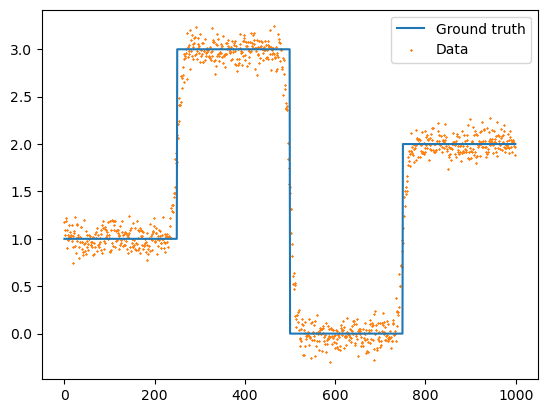

In [3]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.legend()
plt.show()

# Define regularization matrix

In [4]:
Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator

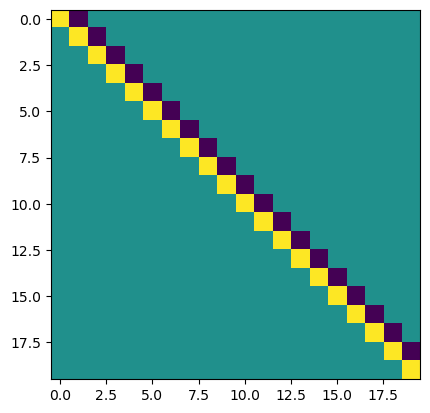

In [5]:
plt.imshow(Lmat.toarray()[:20,:20])
plt.show()

# Use solver

In [6]:
mmgks_solver = MMGKS(A, L, noisy_signal, noise_var=noise_var)
data = mmgks_solver.solve(n_iter=50, epsilon=1e-2, q=1.0, x_true=ground_truth, regparam="gcv", plotting=True, pdf_name="mgcv_1d_deblurring_mmgks.pdf", gcv_gamma=0.1, helping=True)

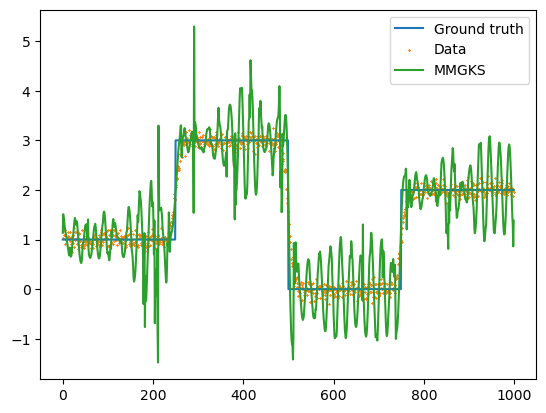

In [7]:
plt.plot(grid, ground_truth, label="Ground truth", color="C0")
plt.scatter(grid, noisy_signal, marker="x", label="Data", color="C1", alpha=1.0, s=0.5)
plt.plot(grid, data["x"], label="MMGKS", color="C2")
plt.legend()
plt.show()
plt.show()

In [9]:
data["rre_history"][-1]

0.2951341168922612

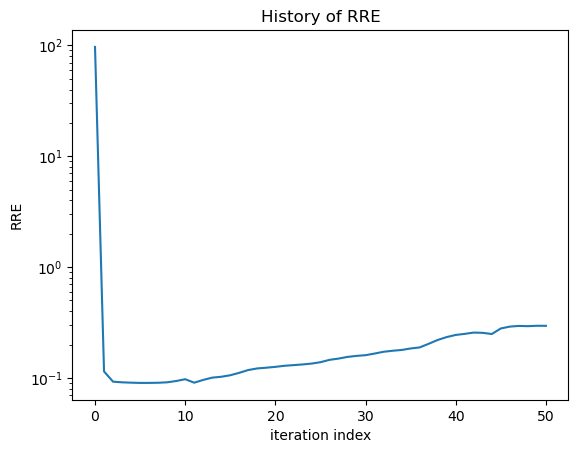

In [10]:
plt.plot(data["rre_history"])
plt.yscale("log")
plt.title("History of RRE")
plt.ylabel("RRE")
plt.xlabel("iteration index")
plt.show()

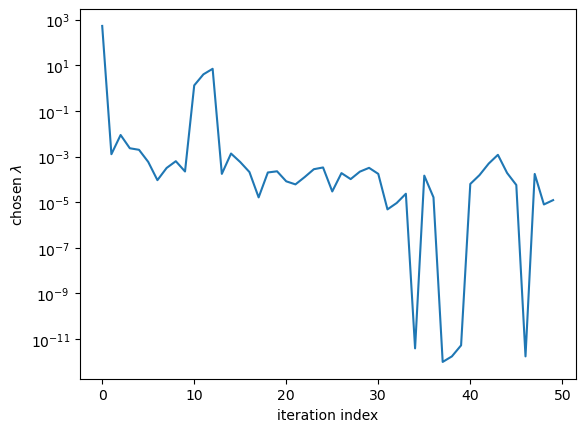

In [11]:
plt.plot(data["lambda_history"])
plt.yscale("log")
plt.xlabel("iteration index")
plt.ylabel("chosen $\\lambda$")
plt.show()

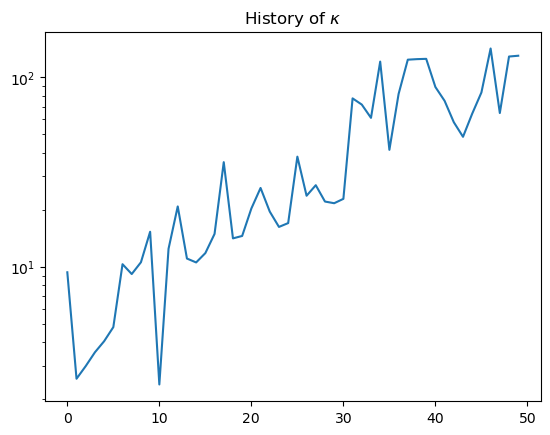

In [12]:
plt.plot(data["cond_ests"])
plt.yscale("log")
plt.title("History of $\\kappa$")
plt.show()